# Download of Database With Kaggle API and Import Python Libraries

In [1]:
!kaggle --version

Kaggle CLI 2.0.2


In [2]:
!pip install -U kaggle

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 4.3 MB/s eta 0:00:00
  Attempting uninstall: kaggle
    Found existing installation: kaggle 2.0.2
    Uninstalling kaggle-2.0.2:
      Successfully uninstalled kaggle-2.0.2


In [3]:
#Import libraries
import os
import zipfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from itertools import combinations
from IPython.display import display

#Setting Kaggle API token
os.environ["KAGGLE_API_TOKEN"] = "REDACTED"

#Download the competition dataset
!kaggle datasets download psparks/instacart-market-basket-analysis

#Create a folder for the extracted files
os.makedirs("data", exist_ok=True)

#Extract the ZIP file
with zipfile.ZipFile("instacart-market-basket-analysis.zip", "r") as zip_ref:
    zip_ref.extractall("data")

#Load the CSVs into pandas DataFrames
orders = pd.read_csv("data/orders.csv")
order_products_prior = pd.read_csv("data/order_products__prior.csv")
order_products_train = pd.read_csv("data/order_products__train.csv")
products = pd.read_csv("data/products.csv")
departments = pd.read_csv("data/departments.csv")
aisles = pd.read_csv("data/aisles.csv")

#Verify the data loading
print(orders.head())
print(products.head())

Dataset URL: https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis
License(s): CC0-1.0
100% 197M/197M [00:02<00:00, 99.3MB/s]

   order_id  user_id eval_set  order_number  order_dow  order_hour_of_day  \
0   2539329        1    prior             1          2                  8   
1   2398795        1    prior             2          3                  7   
2    473747        1    prior             3          3                 12   
3   2254736        1    prior             4          4                  7   
4    431534        1    prior             5          4                 15   

   days_since_prior_order  
0                     NaN  
1                    15.0  
2                    21.0  
3                    29.0  
4                    28.0  
   product_id                                       product_name  aisle_id  \
0           1                         Chocolate Sandwich Cookies        61   
1           2                                   All-Seasons Salt   

# Data Validation and Initial Inspection (info, describe, nunique, duplicates, NULL values)

#### This section checks the structure and quality of the following data tables:

*  Orders
*  Order Products Prior
*  Order Products Train
*  Products
*  aisles
*  department









## Orders Table Findings

- The orders table contains 206,209 missing values in `days_since_prior_order`.
- No duplicate rows were identified.
- Missing values are expected because first-time orders do not have a previous order.

In [4]:
# Orders Table

print("Orders:", orders.shape)

orders.info()

display(orders.nunique())

orders.duplicated().sum()

orders.isnull().sum()

Orders: (3421083, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3421083 entries, 0 to 3421082
Data columns (total 7 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   order_id                int64  
 1   user_id                 int64  
 2   eval_set                object 
 3   order_number            int64  
 4   order_dow               int64  
 5   order_hour_of_day       int64  
 6   days_since_prior_order  float64
dtypes: float64(1), int64(5), object(1)
memory usage: 182.7+ MB


,0
order_id,3421083
user_id,206209
eval_set,3
order_number,100
order_dow,7
order_hour_of_day,24
days_since_prior_order,31


,0
order_id,0
user_id,0
eval_set,0
order_number,0
order_dow,0
order_hour_of_day,0
days_since_prior_order,206209


In [5]:
# Preview of Orders table ordered by order_id
orders.sort_values("order_id").head(10)

,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
1868044,1,112108,train,4,4,10,9.0
3355525,2,202279,prior,3,5,9,8.0
3417191,3,205970,prior,16,5,17,12.0
2958007,4,178520,prior,36,1,9,7.0
2593373,5,156122,prior,42,6,16,9.0
370620,6,22352,prior,4,1,12,30.0
2374153,7,142903,prior,11,2,14,30.0
50028,8,3107,prior,5,4,6,17.0
2308534,9,139016,prior,14,0,19,5.0
2249060,10,135442,prior,4,6,8,8.0


In [6]:
# The three distinct categories in eval_set column
print(orders["eval_set"].unique())

['prior' 'train' 'test']


## Order Products Prior Table Findings

- No NULL values
- No duplicate rows were identified
- Shares Order_id with Orders table

In [7]:
# Order Products Prior Table

print("Prior:", order_products_prior.shape)

order_products_prior.info()

display(order_products_prior.nunique())

order_products_prior.duplicated().sum()

order_products_prior.isnull().sum()

Prior: (32434489, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32434489 entries, 0 to 32434488
Data columns (total 4 columns):
 #   Column             Dtype
---  ------             -----
 0   order_id           int64
 1   product_id         int64
 2   add_to_cart_order  int64
 3   reordered          int64
dtypes: int64(4)
memory usage: 989.8 MB


,0
order_id,3214874
product_id,49677
add_to_cart_order,145
reordered,2


,0
order_id,0
product_id,0
add_to_cart_order,0
reordered,0


In [8]:
#Preview of Order Products Prior table ordered by order_id
order_products_prior.head(10)

,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0
3,2,45918,4,1
4,2,30035,5,0
5,2,17794,6,1
6,2,40141,7,1
7,2,1819,8,1
8,2,43668,9,0
9,3,33754,1,1


## Order Products Train Table Findings

- No NULL values
- No duplicate rows were identified
- Shares Order_id with Orders table
- Shares Order_id and Product_id with Order Products Prior

In [9]:
# Order Products Train Table

print("Train:", order_products_train.shape)

order_products_train.info()

display(order_products_train.nunique())

order_products_train.duplicated().sum()

order_products_train.isnull().sum()

Train: (1384617, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1384617 entries, 0 to 1384616
Data columns (total 4 columns):
 #   Column             Non-Null Count    Dtype
---  ------             --------------    -----
 0   order_id           1384617 non-null  int64
 1   product_id         1384617 non-null  int64
 2   add_to_cart_order  1384617 non-null  int64
 3   reordered          1384617 non-null  int64
dtypes: int64(4)
memory usage: 42.3 MB


,0
order_id,131209
product_id,39123
add_to_cart_order,80
reordered,2


,0
order_id,0
product_id,0
add_to_cart_order,0
reordered,0


## Products Table Findings

- No NULL values
- No duplicate rows were identified
- Shares product_id with Order Products Prior table
- Shares aisle_id with Aisles table

In [10]:
# Products Table

print("Products:", products.shape)

products.info()

display(products.nunique())

products.duplicated().sum()

products.isnull().sum()

Products: (49688, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49688 entries, 0 to 49687
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   product_id     49688 non-null  int64 
 1   product_name   49688 non-null  object
 2   aisle_id       49688 non-null  int64 
 3   department_id  49688 non-null  int64 
dtypes: int64(3), object(1)
memory usage: 1.5+ MB


,0
product_id,49688
product_name,49688
aisle_id,134
department_id,21


,0
product_id,0
product_name,0
aisle_id,0
department_id,0


## Aisles Table Findings

- No NULL values
- No duplicate rows were identified
- Shares aisle_id with Products table

In [11]:
# Aisles Table

print("Aisles:", aisles.shape)

aisles.info()

display(aisles.nunique())

aisles.duplicated().sum()

aisles.isnull().sum()

Aisles: (134, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 134 entries, 0 to 133
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   aisle_id  134 non-null    int64 
 1   aisle     134 non-null    object
dtypes: int64(1), object(1)
memory usage: 2.2+ KB


,0
aisle_id,134
aisle,134


,0
aisle_id,0
aisle,0


## Departments Table Findings

- No NULL values
- No duplicate rows were identified
- Shares department_id with Products table

In [12]:
# Departments Table

print("Departments:", departments.shape)

departments.info()

display(departments.nunique())

departments.duplicated().sum()

departments.isnull().sum()

Departments: (21, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   department_id  21 non-null     int64 
 1   department     21 non-null     object
dtypes: int64(1), object(1)
memory usage: 468.0+ bytes


,0
department_id,21
department,21


,0
department_id,0
department,0


# Customer Shopping Behavior


## Shopping Behaviors of Customers from Order

Activity trends of orders made during the week indicates high number of orders on Day 0 and Day 1. Given this trend, we assume

*   0 = Saturday
*   1 = Sunday

with the assumption that groceries are bought on weekends.


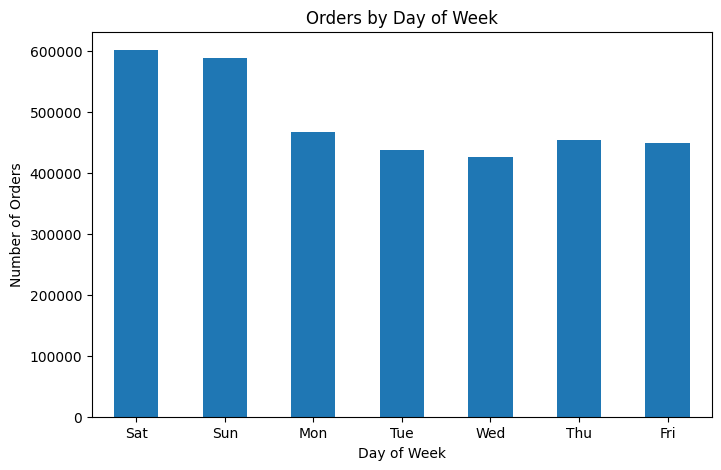

In [13]:
# Trends within Orders by DOW
# Assumption made that date starts with Saturday
day_names = {
    0: "Sat",
    1: "Sun",
    2: "Mon",
    3: "Tue",
    4: "Wed",
    5: "Thu",
    6: "Fri",
}

count = orders["order_dow"].value_counts().sort_index()

count.index = count.index.map(day_names)

count.plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Orders by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.show()

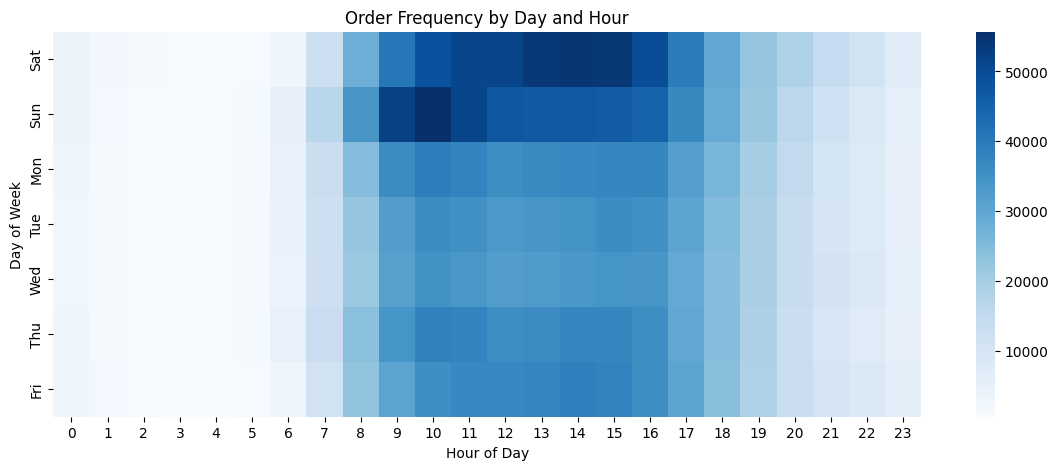

In [14]:
# Given DOW broken down to 24 hours, which hour of the day of the week is most active amongst shoppers?
# Assumption made that date starts with Saturday
day_names = {
    0: "Sat",
    1: "Sun",
    2: "Mon",
    3: "Tue",
    4: "Wed",
    5: "Thu",
    6: "Fri",
}

heat = orders.pivot_table(
    index="order_dow",
    columns="order_hour_of_day",
    values="order_id",
    aggfunc="count"
)

# Rename the index
heat.index = heat.index.map(day_names)

plt.figure(figsize=(14, 5))
sns.heatmap(heat, cmap="Blues")

plt.title("Order Frequency by Day and Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Day of Week")
plt.show()

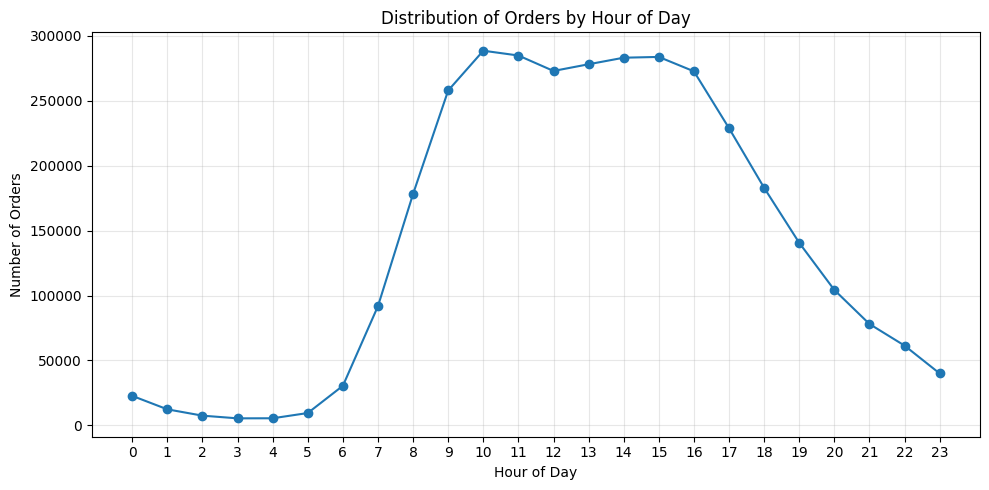

In [15]:
# Accumulated activity split by hour of the day
orders["order_hour_of_day"].value_counts().sort_index().plot(
    kind="line",
    figsize=(10, 5),
    marker="o"
)

plt.title("Distribution of Orders by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Orders")
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()